# 04 – Regime Discovery

**Project:** Technology & Fintech Market Intelligence and Regime Analyzer  
**Phase:** 4 (partial) – Unsupervised regime / behaviour clustering

### Goals
1. Load the feature panel produced by notebook 03  
2. Discover behavioural regimes with unsupervised clustering (K-Means)  
3. Compare discovered clusters with the rule-based regime labels  
4. Assess separation, stability and interpretability  
5. Persist regime assignments and diagnostics  

### Prerequisites
- Notebooks 01–03 completed  
- `data/processed/feature_panel.parquet` and `feature_metadata.json` exist

In [ ]:
# Cell 1 – Imports & setup
from __future__ import annotations

import sys
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings
from config.constants import REGIME_LABELS, RANDOM_SEED, FEATURE_GROUPS
from src.utils import setup_logging, get_logger, utc_now, ensure_dir, save_json
from src.db.connection import get_client, get_db
from src.db.collections import ensure_indexes
from src.db.analysis_results import save_analysis_result
from src.analysis.regime_discovery import discover_regimes, regime_summary
from src.features.regime_labels import regime_transition_matrix

setup_logging(level="INFO")
logger = get_logger(__name__)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
np.random.seed(RANDOM_SEED)

print("Project root :", PROJECT_ROOT)

Project root : c:\Users\hp\Documents\GitHub\BeneathTheMarket


In [2]:
## 1. Load feature panel & metadata

processed_dir = ensure_dir(settings.PROCESSED_DATA_DIR)
panel_path = processed_dir / "feature_panel.parquet"
meta_path  = processed_dir / "feature_metadata.json"

if not panel_path.exists():
    raise FileNotFoundError(f"{panel_path} not found. Run notebook 03 first.")

panel = pd.read_parquet(panel_path)
# Drop any accidental duplicate columns
panel = panel.loc[:, ~panel.columns.duplicated()].copy()

import json
with open(meta_path, "r", encoding="utf-8") as f:
    feature_meta = json.load(f)

feature_cols = feature_meta["feature_cols"]
# Keep only columns that actually exist and are numeric
feature_cols = [
    c for c in feature_cols
    if c in panel.columns and pd.api.types.is_numeric_dtype(panel[c])
]

print(f"Panel shape     : {panel.shape}")
print(f"Tickers         : {panel['ticker'].nunique()}")
print(f"Feature columns : {len(feature_cols)}")
print(f"Splits          : {panel['split'].value_counts().to_dict()}")
display(panel.head(3))

Panel shape     : (45106, 44)
Tickers         : 38
Feature columns : 38
Splits          : {'train': 31578, 'val': 6764, 'test': 6764}


,ticker,category,ret_1d,log_ret_1d,ret_5d,log_ret_5d,ret_10d,log_ret_10d,ret_21d,log_ret_21d,...,regime_id,corr_market_21d,beta_market_21d,relative_strength_21d,corr_market_63d,beta_market_63d,relative_strength_63d,target_ret_5d,target_dir_5d,split
timestamp,,,,,,,,,,,,,,,,,,,,,
2022-01-10,ANET,Cloud and enterprise infrastructure,0.015910,0.015785,-0.075225,-0.078205,-0.104195,-0.110033,0.022384,0.022138,...,2,NaN,NaN,NaN,NaN,NaN,NaN,-0.033830,0.0,train
2022-01-10,QCOM,Semiconductors and chip design,-0.004046,-0.004054,-0.035068,-0.035698,-0.035689,-0.036342,-0.014156,-0.014257,...,2,NaN,NaN,NaN,NaN,NaN,NaN,-0.004564,0.0,train
2022-01-10,GOOGL,Major technology platforms,0.012060,0.011988,-0.043603,-0.044582,-0.062452,-0.064487,-0.060750,-0.062673,...,1,NaN,NaN,NaN,NaN,NaN,NaN,-0.019265,0.0,train


## 2. Select features for clustering

We use a compact, interpretable subset that captures trend, volatility  
and momentum – avoiding highly collinear or sparse columns.

In [3]:
# Cell 3 – Clustering feature subset
CANDIDATE_FEATURES = [
    # returns / trend
    "ret_5d", "ret_21d", "log_ret_21d",
    # volatility / risk
    "vol_21d", "vol_63d", "max_dd_21d", "dd_from_peak",
    # technical
    "rsi_14", "macd_hist", "sma_21",
    # cross-sectional (if present)
    "corr_market_21d", "beta_market_21d", "relative_strength_21d",
]

cluster_features = [c for c in CANDIDATE_FEATURES if c in feature_cols]
print(f"Using {len(cluster_features)} features for regime discovery:")
print(cluster_features)

# Work on a clean frame (drop rows with NaNs in the chosen features)
work = panel.dropna(subset=cluster_features).copy()
print(f"Rows available for clustering: {len(work)}")

Using 13 features for regime discovery:
['ret_5d', 'ret_21d', 'log_ret_21d', 'vol_21d', 'vol_63d', 'max_dd_21d', 'dd_from_peak', 'rsi_14', 'macd_hist', 'sma_21', 'corr_market_21d', 'beta_market_21d', 'relative_strength_21d']
Rows available for clustering: 44308


## 3. Discover regimes (K-Means)

We fit on the **training split only** to avoid leaking future information  
into the cluster definitions, then assign labels to the full panel.

In [4]:
# Cell 4 – Fit K-Means on train split, predict everywhere
N_REGIMES = 4          # matches the four conceptual labels
train_mask = work["split"] == "train"
X_train = work.loc[train_mask, cluster_features].values
X_all   = work[cluster_features].values

if len(X_train) < 100:
    raise RuntimeError("Not enough training rows for regime discovery.")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_all_s   = scaler.transform(X_all)

kmeans = KMeans(n_clusters=N_REGIMES, random_state=RANDOM_SEED, n_init=20)
kmeans.fit(X_train_s)

work = work.copy()
work["regime_cluster"] = kmeans.predict(X_all_s)

# Silhouette on a sample of the training data (for speed)
sample_idx = np.random.choice(len(X_train_s), size=min(5000, len(X_train_s)), replace=False)
sil = float(silhouette_score(X_train_s[sample_idx], kmeans.labels_[sample_idx]))
print(f"Silhouette score (train sample): {sil:.3f}")
print("Cluster sizes (full panel):")
display(work["regime_cluster"].value_counts().sort_index().to_frame("count"))

Silhouette score (train sample): 0.156
Cluster sizes (full panel):


,count
regime_cluster,
0,7126
1,5388
2,15830
3,15964


## 4. Map numeric clusters → semantic labels

We characterise each cluster by its average return and volatility,  
then assign bull / bear / sideways / high_vol labels.

In [5]:
# Cell 5 – Semantic mapping

# Average behaviour per cluster
char = (
    work.groupby("regime_cluster")[cluster_features]
    .mean()
)
print("Cluster centroids (mean feature values):")
display(char.round(4))

# Simple heuristic: highest avg ret_21d → bull, lowest → bear,
# highest vol among remaining → high_vol, rest → sideways
ret_col = "ret_21d" if "ret_21d" in char.columns else cluster_features[0]
vol_col = "vol_21d" if "vol_21d" in char.columns else cluster_features[1]

ordered_by_ret = char[ret_col].sort_values(ascending=False)
label_map = {}
label_map[int(ordered_by_ret.index[0])] = REGIME_LABELS["bull"]
label_map[int(ordered_by_ret.index[-1])] = REGIME_LABELS["bear"]

remaining = [c for c in ordered_by_ret.index if c not in label_map]
if remaining:
    vol_order = char.loc[remaining, vol_col].sort_values(ascending=False)
    label_map[int(vol_order.index[0])] = REGIME_LABELS["high_vol"]
    for c in vol_order.index[1:]:
        label_map[int(c)] = REGIME_LABELS["sideways"]

work["regime_discovered"] = work["regime_cluster"].map(label_map)
print("\nSemantic label map:", label_map)
print("\nDiscovered regime distribution:")
display(work["regime_discovered"].value_counts().to_frame("count"))

Cluster centroids (mean feature values):


,ret_5d,ret_21d,log_ret_21d,vol_21d,vol_63d,max_dd_21d,dd_from_peak,rsi_14,macd_hist,sma_21,corr_market_21d,beta_market_21d,relative_strength_21d
regime_cluster,,,,,,,,,,,,,
0,0.0685,0.2105,0.1824,0.6791,0.6606,-0.1573,-0.3567,62.8491,1.4747,141.6720,0.6386,1.4171,1.1352
1,-0.0448,-0.1518,-0.1733,0.7386,0.7047,-0.2872,-0.5475,39.5790,-0.9987,132.0607,0.7147,1.4572,0.8799
2,0.0223,0.0736,0.0692,0.3052,0.3389,-0.0793,-0.1538,60.4860,0.4924,186.9173,0.5385,0.6464,1.0213
3,-0.0217,-0.0512,-0.0546,0.3838,0.4053,-0.1428,-0.3230,42.8776,-0.7087,174.4066,0.6159,0.8106,0.9560



Semantic label map: {0: 'upward-trending', 1: 'downward-trending', 3: 'high-volatility', 2: 'range-bound'}

Discovered regime distribution:


,count
regime_discovered,
high-volatility,15964
range-bound,15830
upward-trending,7126
downward-trending,5388


Adjusted Rand Index (rule-based vs discovered): 0.213

Row-normalised crosstab (rule-based → discovered):


regime_discovered,downward-trending,high-volatility,range-bound,upward-trending
regime,,,,
downward-trending,0.241,0.723,0.033,0.003
high-volatility,0.217,0.309,0.199,0.275
range-bound,0.037,0.469,0.457,0.036
upward-trending,0.007,0.070,0.664,0.260


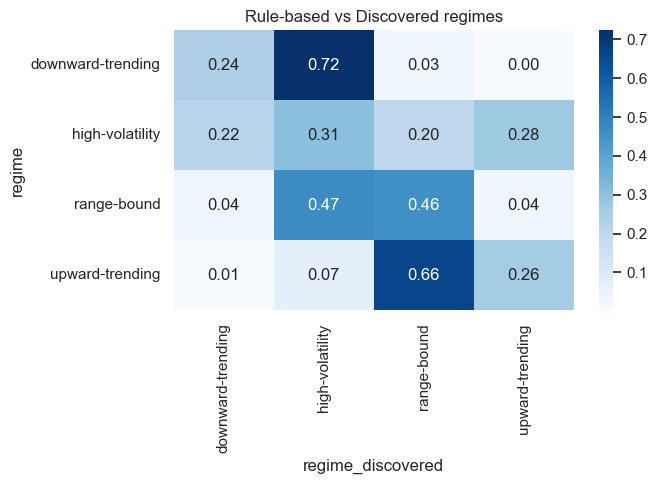

In [6]:
## 5. Compare with rule-based regime labels

if "regime" not in work.columns:
    print("No rule-based 'regime' column found – skipping comparison.")
else:
    # Align labels
    common = work.dropna(subset=["regime", "regime_discovered"])
    ari = adjusted_rand_score(common["regime"], common["regime_discovered"])
    print(f"Adjusted Rand Index (rule-based vs discovered): {ari:.3f}")

    # Confusion-style crosstab
    ct = pd.crosstab(
        common["regime"],
        common["regime_discovered"],
        normalize="index",
    ).round(3)
    print("\nRow-normalised crosstab (rule-based → discovered):")
    display(ct)

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues", ax=ax)
    ax.set_title("Rule-based vs Discovered regimes")
    plt.tight_layout()
    plt.show()

Using target: target_ret_5d


,avg_fwd_ret,std_fwd_ret,count,avg_vol_21d
regime_discovered,,,,
downward-trending,0.0140,0.0985,5388,0.7386
high-volatility,0.0043,0.0636,15964,0.3838
range-bound,0.0040,0.0529,15830,0.3052
upward-trending,0.0068,0.0896,7126,0.6791


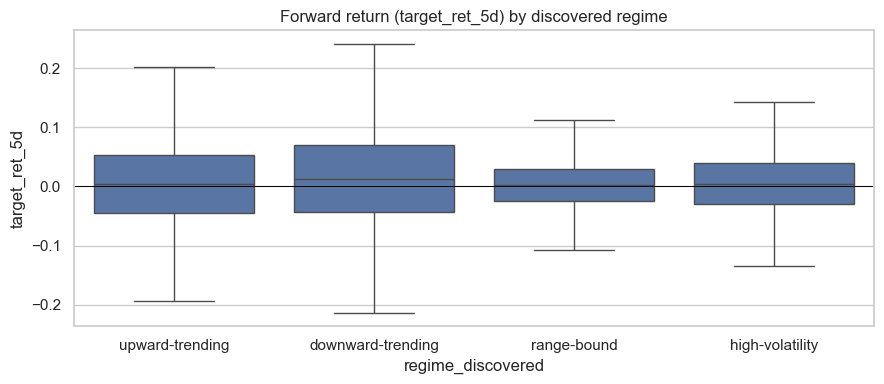

In [7]:
## 6. Regime behaviour – forward returns & risk

target_col = f"target_ret_{feature_meta.get('horizon', 5)}d"
if target_col not in work.columns:
    # fallback
    target_candidates = [c for c in work.columns if c.startswith("target_ret_")]
    target_col = target_candidates[0] if target_candidates else None

if target_col:
    print(f"Using target: {target_col}")
    summary = (
        work.groupby("regime_discovered")[target_col]
        .agg(["mean", "std", "count"])
        .rename(columns={"mean": "avg_fwd_ret", "std": "std_fwd_ret"})
    )
    if "vol_21d" in work.columns:
        summary["avg_vol_21d"] = work.groupby("regime_discovered")["vol_21d"].mean()
    display(summary.round(4))

    # Box-plot of forward returns by regime
    fig, ax = plt.subplots(figsize=(9, 4))
    order = list(REGIME_LABELS.values())
    present = [r for r in order if r in work["regime_discovered"].unique()]
    sns.boxplot(
        data=work,
        x="regime_discovered",
        y=target_col,
        order=present,
        ax=ax,
        showfliers=False,
    )
    ax.axhline(0, color="black", lw=0.7)
    ax.set_title(f"Forward return ({target_col}) by discovered regime")
    plt.tight_layout()
    plt.show()
else:
    print("No target_ret column found.")

In [8]:
## 7. Stability across time (walk-forward silhouette)

# Split the training period into 3 consecutive blocks and re-fit
train_data = work[work["split"] == "train"].copy()
dates = train_data.index.unique().sort_values()
n = len(dates)
blocks = np.array_split(dates, 3)

stability_rows = []
for i, block_dates in enumerate(blocks):
    block = train_data.loc[train_data.index.isin(block_dates), cluster_features].dropna()
    if len(block) < 50:
        continue
    Xs = StandardScaler().fit_transform(block.values)
    km = KMeans(n_clusters=N_REGIMES, random_state=RANDOM_SEED, n_init=10)
    labels = km.fit_predict(Xs)
    sil_b = float(silhouette_score(Xs, labels)) if len(set(labels)) > 1 else np.nan
    stability_rows.append({
        "block": i + 1,
        "n_rows": len(block),
        "silhouette": sil_b,
        "start": str(block_dates.min().date()),
        "end": str(block_dates.max().date()),
    })

stability_df = pd.DataFrame(stability_rows)
print("Walk-forward silhouette by training block:")
display(stability_df)

Walk-forward silhouette by training block:


,block,n_rows,silhouette,start,end
0,1,10260,0.175560,2022-02-09,2023-03-08
1,2,10260,0.149613,2023-03-09,2024-04-04
2,3,10260,0.147602,2024-04-05,2025-05-02


In [10]:
## 8. Transition matrix of discovered regimes

# Use one liquid ticker as illustration
example_ticker = work["ticker"].value_counts().index[0]
ex = work[work["ticker"] == example_ticker]["regime_discovered"].dropna()
trans = regime_transition_matrix(ex)
print(f"Transition counts – {example_ticker}:")
display(trans)

# Normalised
trans_norm = trans.div(trans.sum(axis=1), axis=0).round(3)
print("\nRow-normalised transition probabilities:")
display(trans_norm)

Transition counts – CRM:


regime_discovered,downward-trending,high-volatility,range-bound,upward-trending
regime_discovered,,,,
downward-trending,29,9,0,0
high-volatility,9,495,45,8
range-bound,0,47,448,5
upward-trending,0,6,7,57
NaN,0,1,0,0



Row-normalised transition probabilities:


regime_discovered,downward-trending,high-volatility,range-bound,upward-trending
regime_discovered,,,,
downward-trending,0.763,0.237,0.000,0.000
high-volatility,0.016,0.889,0.081,0.014
range-bound,0.000,0.094,0.896,0.010
upward-trending,0.000,0.086,0.100,0.814
NaN,0.000,1.000,0.000,0.000


In [11]:
## 9. Attach discovered regimes back to the panel & persist

# Align discovered labels onto the original panel index + ticker
regime_map = work[["ticker", "regime_cluster", "regime_discovered"]].copy()
regime_map = regime_map.reset_index().drop_duplicates(subset=["timestamp", "ticker"])

panel_out = panel.reset_index().merge(
    regime_map,
    on=["timestamp", "ticker"],
    how="left",
).set_index("timestamp")

# De-duplicate columns just in case
panel_out = panel_out.loc[:, ~panel_out.columns.duplicated()].copy()

# Save enriched panel
out_path = processed_dir / "feature_panel_with_regimes.parquet"
panel_out.to_parquet(out_path)
print(f"Saved enriched panel → {out_path}")

# Diagnostics document
diagnostics = {
    "run_at": utc_now().isoformat(),
    "n_regimes": N_REGIMES,
    "cluster_features": cluster_features,
    "silhouette_train_sample": sil,
    "label_map": {str(k): v for k, v in label_map.items()},
    "cluster_sizes": work["regime_cluster"].value_counts().to_dict(),
    "discovered_distribution": work["regime_discovered"].value_counts().to_dict(),
    "stability_blocks": stability_rows,
    "adjusted_rand_vs_rule": float(ari) if "ari" in dir() else None,
}

diag_path = processed_dir / "regime_discovery_diagnostics.json"
save_json(diagnostics, diag_path)
print(f"Saved diagnostics → {diag_path}")

# MongoDB summary
save_analysis_result({
    "analysis_type": "regime_discovery",
    "as_of": utc_now().isoformat(),
    "payload": {
        "n_regimes": N_REGIMES,
        "silhouette": sil,
        "label_map": diagnostics["label_map"],
        "discovered_distribution": diagnostics["discovered_distribution"],
    },
})
print("Regime-discovery summary written to MongoDB")

Saved enriched panel → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\feature_panel_with_regimes.parquet
Saved diagnostics → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\regime_discovery_diagnostics.json
2026-10-12 11:55:33 | INFO     | src.db.connection | Connected to local MongoDB at mongodb://localhost:27017 (db=tech_fintech_market_intel)
Regime-discovery summary written to MongoDB


## 10. Acceptance criteria (Notebook 04)

| Criterion | Status |
|-----------|--------|
| Unsupervised regimes fitted on train only | Cell 4 |
| Semantic labels assigned | Cell 5 |
| Comparison with rule-based regimes | Cell 6 |
| Economic interpretation (forward returns) | Cell 7 |
| Temporal stability check | Cell 8 |
| Results persisted | Cell 10 |


In [12]:
print("Notebook 04 finished successfully.")
print(f"Discovered regimes: {list(work['regime_discovered'].dropna().unique())}")
print(f"Silhouette (train sample): {sil:.3f}")

Notebook 04 finished successfully.
Discovered regimes: ['high-volatility', 'range-bound', 'downward-trending', 'upward-trending']
Silhouette (train sample): 0.156
